# 03 — On/Off-policy Monte Carlo Control

On-policy ε-soft Q와 Off-policy Weighted-IS Greedy Target Q를 각각 학습한다.
Episode 중에는 Q/epsilon을 고정하고, 완료 후 Learner가 갱신한다. 두 실행은 별도 Model/Counts와 경험을 쓴다.
Off-policy Control의 역순 IS/Greedy 중단 조건은 기존 Learner에 구현돼 있다.

### 실행 설정
`MODULARRL_FAST=1`은 CI용 FAST, 기본값은 FULL입니다. 각 Notebook은 독립 Kernel에서 실행합니다. 처음부터 Run All하면 RNG·Model·학습 상태를 다시 만듭니다.

In [1]:
from pathlib import Path
import os, sys, json
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import gymnasium as gym
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from copy import deepcopy
from collections import deque
from modular_rl import Model
from modular_rl import representations as R, estimators as E, selectors as S
from modular_rl import buffers as B, targets as T, updates as U, learners as L
from modular_rl.data import Transition, Episode
from modular_rl.dp import policy_evaluation, policy_iteration, value_iteration, uniform_policy, action_values
from notebooks.gymnasium.tutorial_utils import (frozenlake_mdp, evaluate, history, record, frozen_report, neural_report)
FAST = os.environ.get('MODULARRL_FAST', '0') == '1'  # 기본 FULL, CI는 FAST=1
SEED = 7
GAMMA = .99
np_rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.close('all')
print({'mode': 'FAST' if FAST else 'FULL', 'seed': SEED, 'gamma': GAMMA, 'device': 'cpu'})

{'mode': 'FAST', 'seed': 7, 'gamma': 0.99, 'device': 'cpu'}


In [2]:
env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=1000)
eval_env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=100)
N_STATES, N_ACTIONS = int(env.observation_space.n), int(env.action_space.n)
print(env.observation_space, env.action_space)
desc = env.unwrapped.desc.copy()

Discrete(16) Discrete(4)


In [3]:
models = {name: Model(R.Identity(), E.TabularQ(N_STATES,N_ACTIONS), S.EpsilonGreedy(1.)).double()
          for name in ('on-policy','off-policy')}
return_generator = T.MCReturn(GAMMA)
learners = {'on-policy': L.MCControl(models['on-policy'], return_generator),
            'off-policy': L.OffPolicyMCControl(models['off-policy'], return_generator)}
logs, results = {}, {}

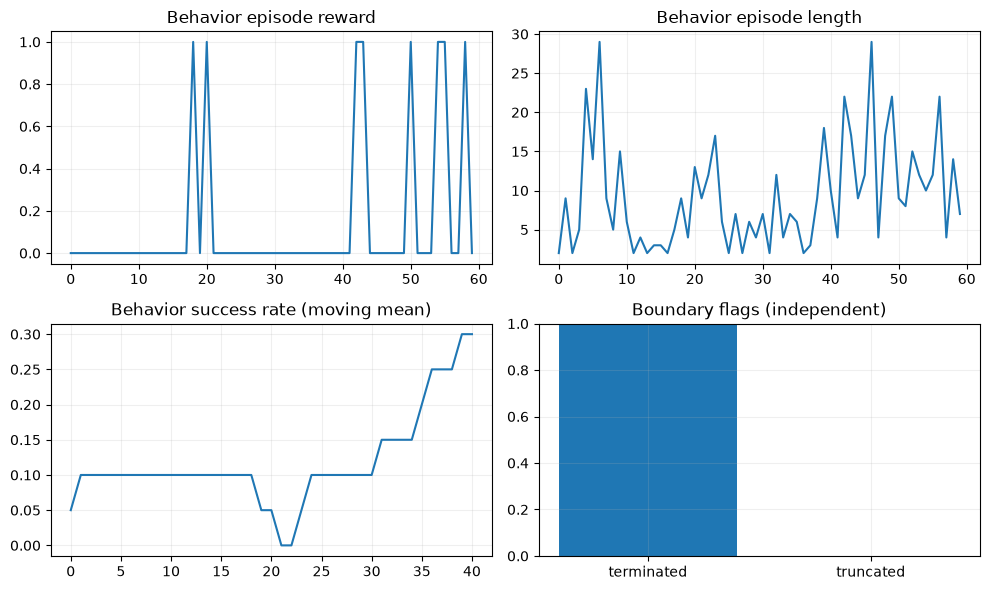

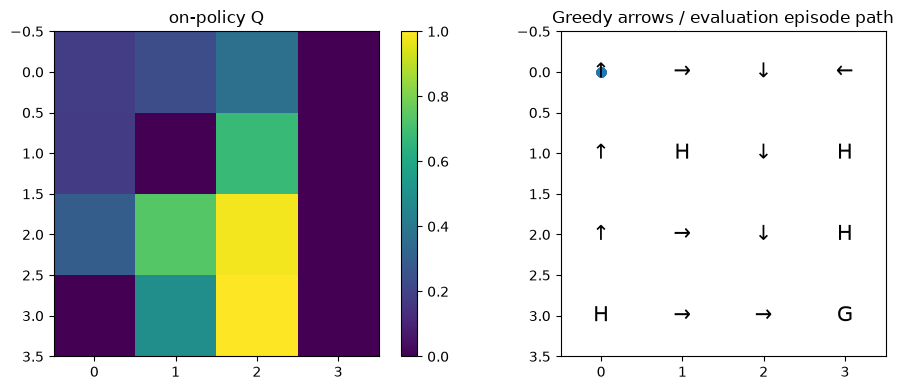

on-policy Q [[0.1357 0.0752 0.1624 0.1822]
 [0.     0.     0.2344 0.    ]
 [0.1189 0.3699 0.     0.2401]
 [0.     0.     0.     0.    ]
 [0.086  0.0878 0.     0.1797]
 [0.     0.     0.     0.    ]
 [0.     0.6725 0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.1941 0.2955]
 [0.     0.49   0.7351 0.    ]
 [0.4851 0.9816 0.     0.6341]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.495  0.4851]
 [0.4803 0.     1.     0.9801]
 [0.     0.     0.     0.    ]]
RESULT {"environment_steps": 560, "episodes": 60, "evaluation_mean_reward": 0.0, "evaluation_success": 0.0, "terminated_rate": 1.0, "truncated_rate": 0.0}


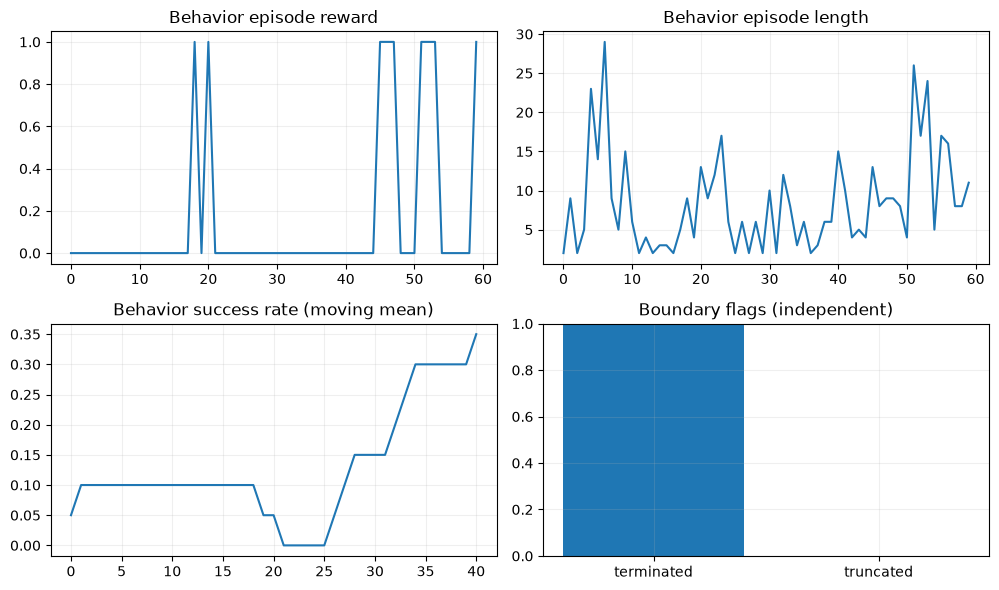

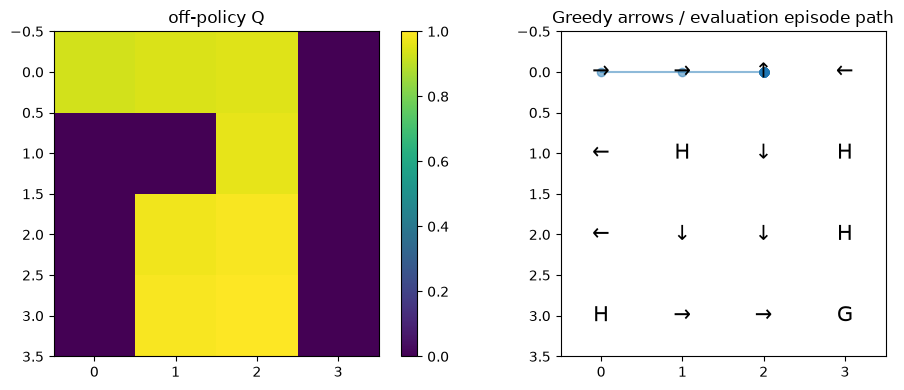

off-policy Q [[0.     0.     0.9321 0.9227]
 [0.     0.     0.9415 0.    ]
 [0.     0.9512 0.     0.9521]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.961  0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.9801 0.9801 0.    ]
 [0.9703 0.99   0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.99   0.    ]
 [0.9801 0.     1.     0.9801]
 [0.     0.     0.     0.    ]]
RESULT {"environment_steps": 507, "episodes": 60, "evaluation_mean_reward": 0.0, "evaluation_success": 0.0, "terminated_rate": 1.0, "truncated_rate": 0.0}


In [4]:
for name, model in models.items():
    torch.manual_seed(SEED)
    log = history()
    for episode_index in range(60 if FAST else 5000):
        model.action_selector.epsilon = max(.1, 1.-episode_index/(100 if FAST else 3000))
        observation, _ = env.reset(seed=SEED if episode_index == 0 else None)
        transitions, total = [], 0.
        while True:
            selected = model.act(observation)
            next_observation, reward, terminated, truncated, _ = env.step(selected.action.item())
            reward = float(reward)  # 학습 reward의 floating 계약
            transitions.append(Transition(observation, selected.action, reward, next_observation, terminated, truncated, selected.log_prob))
            total += reward; observation = next_observation
            if terminated or truncated: break
        episode = Episode(transitions)
        if not episode.terminated: raise RuntimeError('MC truncation: 실험을 중단합니다.')
        learners[name].learn(episode)
        record(log, total, len(transitions), terminated, truncated)
    model.eval()
    evaluation = evaluate(eval_env, lambda state: model.act(state, deterministic=True).action.item(), episodes=5 if FAST else 100)
    results[name] = frozen_report(desc, log, model.estimator.q_table.numpy(), evaluation,
                                  greedy_actions=model.estimator.q_table.argmax(-1).numpy(), label=name+' Q')
    logs[name] = log
env.close(); eval_env.close()

### 이번 조합에서 드러난 API 특성
같은 learn(episode) 형태지만 sample average Count와 Weighted-IS C의 의미는 다르다. Behavior 확률은 Model.act 출력으로 자연스럽게 보존된다. Episode 소유권은 Episode가 확보하며 별도 Replay는 사용하지 않는다.

### API 사용성 기록 — 아래 빈칸을 직접 수정해 보세요

|질문|실행 후 관찰/개선 제안|
|---|---|
|Model 생성이 자연스러운가?| |
|Learner 구성은 직관적인가?| |
|TargetGenerator를 선택하기 쉬운가?| |
|Buffer의 사용법이 일관적인가?| |
|Experience 자료형을 직접 조작할 필요가 있는가?| |
|학습 호출이 간결한가?| |
|Algorithm-specific 코드가 얼마나 필요한가?| |
|불필요한 자료형 변환이 존재하는가?| |
|API만 보고 학습 과정이 이해되는가?| |
|공용 컴포넌트로 옮길 필요가 있는 코드가 있는가?| |

FAST는 연결과 Shape 검사용이며 성능 판정이 아니다. FULL은 실제 학습용이다.
Seed 하나의 성공률로 알고리즘의 정확성을 판단하지 않는다. `terminated`와 `truncated`는
독립적인 flag이며 실제 마지막 관측을 저장한다. 아래 helper는 시각화·평가만 담당하고 학습을 숨기지 않는다.